# Exploration IBM Telco
SAIM Bahaeddine — SOENFO 2026–2027. Exécuter depuis notebooks/ ou la racine.
Les données sont acquises séparément avec `poetry run telcoguard download`.
L'EDA ne modifie pas le pipeline ; aucun identifiant individuel n'est affiché.

In [1]:
from pathlib import Path

import pandas as pd

from telcoguard.data.validation import validate_dataset

root = Path.cwd() if Path("data/raw/telco.csv").exists() else Path.cwd().parent
df = validate_dataset(pd.read_csv(root / "data/raw/telco.csv"))
print(f"Dimensions : {df.shape}")
print(df.drop(columns="customerID").dtypes.to_string())

Dimensions : (7043, 21)
gender               object
SeniorCitizen       float64
Partner              object
Dependents           object
tenure              float64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object


In [2]:
print("Valeurs manquantes :")
print(df.isna().sum().to_string())
print("Distribution du churn :")
print(df.Churn.value_counts().to_string())
print(df.Churn.value_counts(normalize=True).to_string())

Valeurs manquantes :
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
Distribution du churn :
Churn
No     5174
Yes    1869
Churn
No     0.73463
Yes    0.26537


In [3]:
print(df.describe().to_string())
print(pd.crosstab(df.Contract, df.Churn, normalize="index").to_string())
print(pd.crosstab(df.InternetService, df.Churn, normalize="index").to_string())

       SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count    7043.000000  7043.000000     7043.000000   7032.000000
mean        0.162147    32.371149       64.761692   2283.300441
std         0.368612    24.559481       30.090047   2266.771362
min         0.000000     0.000000       18.250000     18.800000
25%         0.000000     9.000000       35.500000    401.450000
50%         0.000000    29.000000       70.350000   1397.475000
75%         0.000000    55.000000       89.850000   3794.737500
max         1.000000    72.000000      118.750000   8684.800000
Churn                 No       Yes
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319
Churn                  No       Yes
InternetService                    
DSL              0.810409  0.189591
Fiber optic      0.581072  0.418928
No               0.925950  0.074050


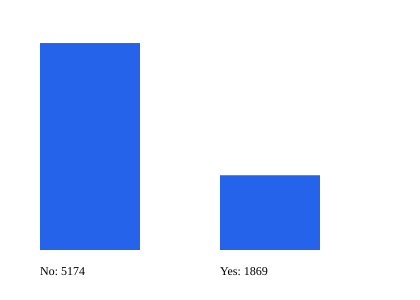

In [4]:
from IPython.display import SVG, display

counts = df.Churn.value_counts()
bars = ""
for i, (label, count) in enumerate(counts.items()):
    x = 40 + i * 180
    height = count / 25
    bars += (
        f'<rect x="{x}" y="{250 - height}" width="100" height="{height}" fill="#2563eb"/>'
        f'<text x="{x}" y="275">{label}: {count}</text>'
    )
display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="420" height="300">{bars}</svg>'))

## Interprétation et limites
Comparer proportions, valeurs manquantes et contrats. Une association observée n'est pas causale. Le déséquilibre justifie precision, recall, F1 et ROC-AUC en complément de l'accuracy. Ne pas choisir un seuil après consultation répétée du test final. Les données pédagogiques ne garantissent pas la représentativité.